# Intro to Neurocomputation: The Hodgkin-Huxley Squid Giant Axon

This tutorial is designed to introduce you to the biophysics of action potential generation and propagation using the classical Hodgkin-Huxley (H-H) model in the **NEURON** simulation environment.

### Objectives:
1. Understand how membrane parameters ($g_{Na}$, $g_{K}$, etc.) affect the action potential waveform.
2. Observe how an action potential propagates actively along a multi-segment axon over space and time.

*Note*. This code was generated by Google Gemini with modifications from Jon Moler and Daniel Leal Serrano

In [ ]:
# Install the NEURON simulator package
# See https://pypi.org/project/neuron/

SyntaxError: invalid syntax (2643763065.py, line 2)

## Part 1: Interactive Membrane Parameters

Below, we create a single axon compartment (soma/section) with Hodgkin-Huxley mechanisms (`hh`). Use the sliders to change key parameters and observe how the action potential adapts!

Key: We can model the whole cell membrane as an equivalent circuit! This allows us to abstract the cell into a set of functions that we can then use to make a digital cell.


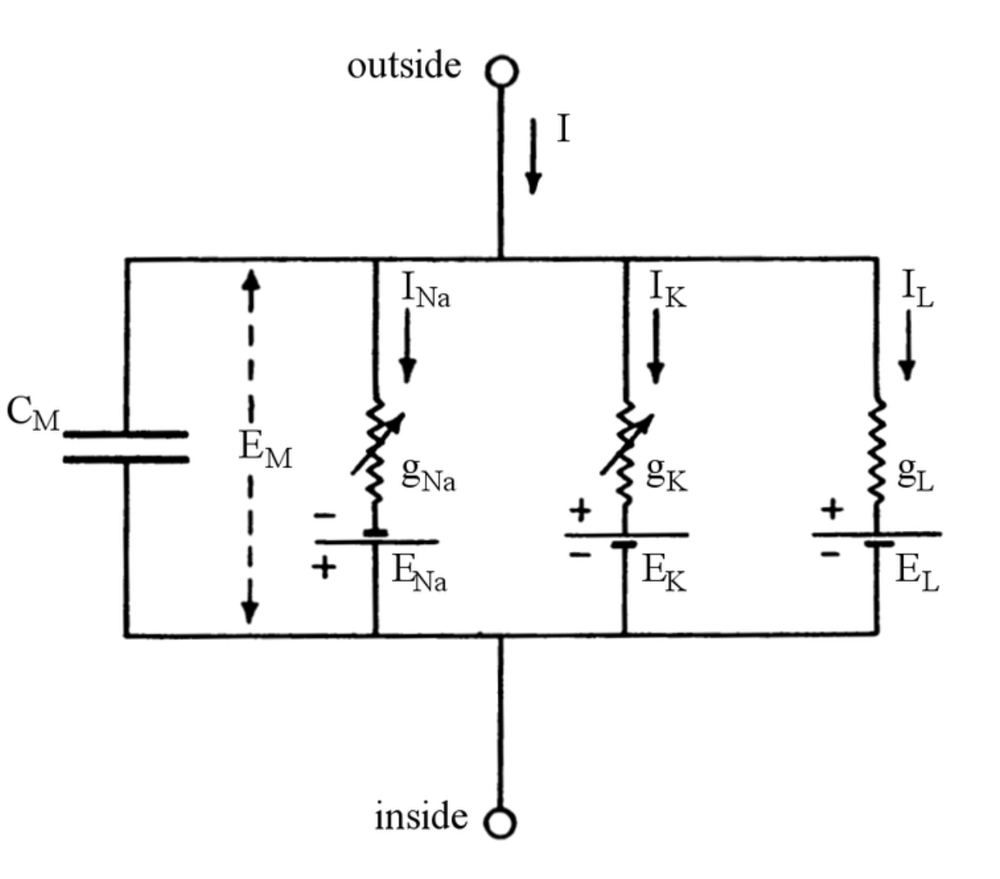

Graham, Anthony. (2010). Biocompatible Low-Cost CMOS Electrodes for Neuronal Interfaces, Cell Impedance and Other Biosensors. 10.13140/RG.2.2.10385.25444.

In [ ]:
# Start by importing all of the necessary packages
import numpy as np
import matplotlib.pyplot as plt
from neuron import h as n
import ipywidgets as widgets
from ipywidgets import interactive

In [ ]:
# Lets set up our basic model, no parameters or plotting yet

# Initialize NEURON standard run controls
n.load_file('stdrun.hoc')

# Create a single compartment axon
axon = n.Section(name='axon')
axon.L = 100    # length in microns
axon.diam = 500 # diameter in microns
axon.Ra = 100   # axial resistivity in ohm-cm

# Insert Hodgkin-Huxley channels
axon.insert('hh');

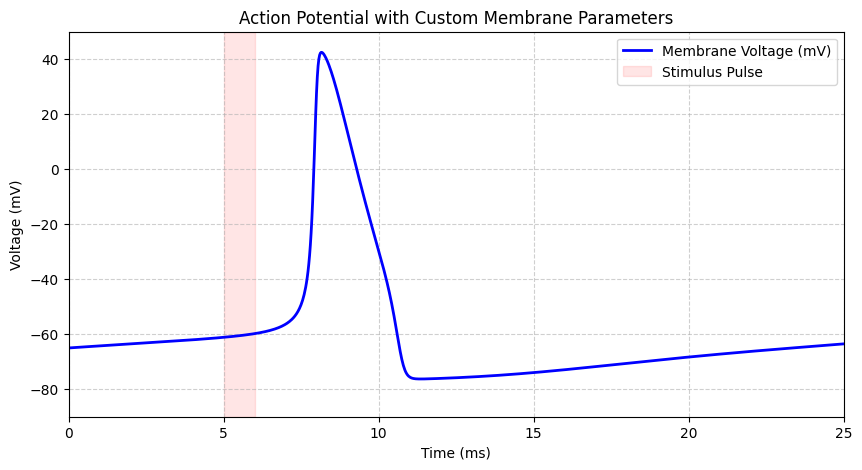

In [ ]:
# Here is where we will begin to play with some parameters. Below, we will find
# 8 lines of 'user parameters' that we can mess with. I have pre-populated each
# field with their 'chosen value' in the HxH paper "A Quantitative Description of
# Membrane Current and its Application to Conduction and Excitation in Nerve
# (pg. 520, Table 3)

gnabar_hh = 200
gkbar_hh = 36
gl_hh = 0.3
cm = 1

# For fun, you can try some different values from a different paper, just to see
# what happens. https://doi.org/10.1371/journal.pone.0277772 (Table 2, Fast Spindles)
# gnabar_hh = 90
# gkbar_hh = 10
# gl_hh = 0.01
# cm = 1

# Convert to the appropriate units, set the parameters in the established 'axon' model
axon.gnabar_hh = gnabar_hh*10**-3
axon.gkbar_hh = gkbar_hh*10**-3
axon.gl_hh = gl_hh*10**-3
axon.cm = cm

# Here you set up stimulus parameters. What and where you apply current, how long
# you wait until you apply that current, how long the stimulation will last, and
# how much current you will inject.
# TRY IT: Change amp to 0 and run to watch the cell stay quiet!
delay = 5   # ms
dur = 1     # ms
amp = 00    # nA

# Things to try...
# 1. What happens if you change your stimulus amplitude to 0?
# 2. What happens if you keep the stimulation amplitude at 0, but
#    also alter the Sodium current to be a higher value? (try gnabar_hh = 200)
#    Think about sodium's role in the action potential. If you increase its membrane
#    conductance, why do you see the change in the activity of the neuron?

stim = n.IClamp(axon(0.0)) # Choose where to put el stimulus-o
stim.delay = delay
stim.dur = dur
stim.amp = amp

# Vectors for recording variables
v_vec = n.Vector().record(axon(0.0)._ref_v)
t_vec = n.Vector().record(n._ref_t)

# Run simulation - We initialize at -65 mV to stabilize the resting potential!
n.finitialize(-65)
n.continuerun(25)

# Plot results
plt.figure(figsize=(10, 5))
plt.plot(t_vec, v_vec, 'b-', linewidth=2, label='Membrane Voltage (mV)')
plt.axvspan(stim.delay, stim.delay + stim.dur, color='red', alpha=0.1, label='Stimulus Pulse')
plt.title('Action Potential with Custom Membrane Parameters')
plt.xlabel('Time (ms)')
plt.ylabel('Voltage (mV)')
plt.xlim(0, 25)
plt.ylim(-90, 50)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

In [ ]:
# Now, typing in stuff and Ctl+Enter-ing your way to victory in life is all well
# and good, but sometimes it's worth it to add some quality of life features to
# our code. To this end, we will take our code from above and put it inside a
# defined 'function', then call that function using a nifty little interactive
# plot with sliders. This way, we can play around with some parameters in real time.

In [ ]:
# Initialize NEURON standard run controls
n.load_file('stdrun.hoc')

def run_hh_simulation(gnabar, gkbar, gl, cm):
    # Create a single compartment axon
    axon = n.Section(name='axon')
    axon.L = 100    # length in microns
    axon.diam = 100 # diameter in microns
    axon.Ra = 100   # axial resistivity in ohm-cm

    # Insert Hodgkin-Huxley channels
    axon.insert('hh')

    # Apply user parameters
    axon.gnabar_hh = gnabar
    axon.gkbar_hh = gkbar
    axon.gl_hh = gl
    axon.cm = cm

    # Set up a stimulus (Current Clamp)
    stim = n.IClamp(axon(0.5))
    stim.delay = 5   # ms
    stim.dur = 1     # ms
    stim.amp = 10    # nA

    # Vectors for recording variables
    v_vec = n.Vector().record(axon(0.5)._ref_v)
    t_vec = n.Vector().record(n._ref_t)

    # Run simulation
    n.finitialize(-65)
    n.continuerun(25)

    # Plot results
    plt.figure(figsize=(10, 5))
    plt.plot(t_vec, v_vec, 'b-', linewidth=2, label='Membrane Voltage (mV)')
    plt.axvspan(stim.delay, stim.delay + stim.dur, color='red', alpha=0.1, label='Stimulus Pulse')
    plt.title('Action Potential with Custom Membrane Parameters')
    plt.xlabel('Time (ms)')
    plt.ylabel('Voltage (mV)')
    plt.xlim(0, 25)
    plt.ylim(-90, 50)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.show()

# Create interactive widget controls
interactive_plot = interactive(
    run_hh_simulation,
    gnabar=widgets.FloatSlider(value=0.12, min=0.0, max=0.30, step=0.01, description='Na Cond (S/cm²)'),
    gkbar=widgets.FloatSlider(value=0.036, min=0.0, max=0.10, step=0.005, description='K Cond (S/cm²)'),
    gl=widgets.FloatSlider(value=0.0003, min=0.0, max=0.001, step=0.0001, description='Leak Cond (S/cm²)', readout_format='.4f'),
    cm=widgets.FloatSlider(value=1.0, min=0.1, max=3.0, step=0.1, description='Capacitance (µF/cm²)')
)

display(interactive_plot)

interactive(children=(FloatSlider(value=0.12, description='Na Cond (S/cm²)', max=0.3, step=0.01), FloatSlider(…

## Part 2: Action Potential Propagation Animation

Next, we model a long axon with 100 segments to show how an action potential initiated at one end propagates down the cable. We will generate an animation of the action potential traveling along the axon.

In [ ]:
import matplotlib.animation as animation
from IPython.display import HTML

# Create a long axon section
axon = n.Section(name='axon')
axon.nseg = 101 # Multiple segments to observe propagation
axon.L = 10000  # 10 mm length
axon.diam = 10  # 10 microns diameter
axon.insert('hh')

# Stimulate one end (0.0)
# If you want to see wierd things happen, try playing with this (0.0) value
stim = n.IClamp(axon(0.5))
stim.delay = 1
stim.dur = 2
stim.amp = 5

# Record from all nodes across space
x_coords = [seg.x * axon.L for seg in axon]

# Let's run and record state profiles at each time step using a customizable recording loop
v_data = []
t_vec = []

def record_step():
    v_data.append([seg.v for seg in axon])
    t_vec.append(n.t)

# Run custom loop and record membrane potential over time
n.finitialize(-65)
record_step()

while n.t < 15:
    n.fadvance()
    record_step()

# Convert to numpy array for easier slicing
v_array = np.array(v_data)

# Set up figure for animation
fig, ax = plt.subplots(figsize=(10, 5))
line, = ax.plot(x_coords, v_array[0], 'r-', linewidth=2.5)
ax.set_xlim(0, axon.L)
ax.set_ylim(-90, 55)
ax.set_title('Action Potential Propagation Along Squid Axon')
ax.set_xlabel('Position along axon (µm)')
ax.set_ylabel('Membrane Potential (mV)')
ax.grid(True, linestyle='--', alpha=0.5)

# Animation helper function
def update(frame):
    # Downsample frames to make the video render smoothly
    step_idx = int(frame * (len(v_array) / 100))
    step_idx = min(step_idx, len(v_array) - 1)
    line.set_ydata(v_array[step_idx])
    ax.set_title(f'Action Potential Propagation (Time = {t_vec[step_idx]:.2f} ms)')
    return line,

# Create the animation
ani = animation.FuncAnimation(fig, update, frames=100, interval=60, blit=True)
plt.close(fig) # Prevent static frame display

# Display the animation directly inside Colab
HTML(ani.to_jshtml())

##Part 3: Inactivation of VGNaCs Prevents Back Propagation

Same simulation as part 2 with a state of Na channel inactivation.

In [ ]:
# Create a long axon section
axon_inact = n.Section(name='axon_inact')
axon_inact.nseg = 101 # Multiple segments to observe spatial propagation
axon_inact.L = 10000  # 10 mm length
axon_inact.diam = 10  # 10 microns diameter
axon_inact.insert('hh')

# 1. Primary stimulus at one end (position 0.0) to initiate the first wave
stim1 = n.IClamp(axon_inact(0.0))
stim1.delay = 1.0  # ms
stim1.dur = 2.0    # ms
stim1.amp = 5.0    # nA

# 2. Secondary stimulus in the middle (position 0.5) to test back-propagation
# This is timed to trigger while the Na+ channels to the left are still inactivated
stim2 = n.IClamp(axon_inact(0.5))
stim2.delay = 6.0  # ms (triggered shortly after the first wave passes the center)
stim2.dur = 2.0    # ms
stim2.amp = 6.0    # nA

# Record spatial positions
x_coords = [seg.x * axon_inact.L for seg in axon_inact]

# Lists to record state profiles over time
v_data = []
t_vec = []

def record_step():
    v_data.append([seg.v for seg in axon_inact])
    t_vec.append(n.t)

# Run simulation loop
n.finitialize(-65)
record_step()

while n.t < 18:
    n.fadvance()
    record_step()

v_array = np.array(v_data)

# Set up figure for animation
fig, ax = plt.subplots(figsize=(10, 5))
line, = ax.plot(x_coords, v_array[0], 'r-', linewidth=2.5)
ax.set_xlim(0, axon_inact.L)
ax.set_ylim(-90, 55)
ax.set_title('Action Potential Propagation & Inactivation Block')
ax.set_xlabel('Position along axon (µm)')
ax.set_ylabel('Membrane Potential (mV)')
ax.grid(True, linestyle='--', alpha=0.5)

# Indicator lines for stimulation sites
ax.axvline(1000, color='blue', linestyle=':', alpha=0.7, label='Stimulus 1 (t=1ms)')
ax.axvline(5000, color='purple', linestyle=':', alpha=0.7, label='Stimulus 2 (t=6ms)')
ax.legend(loc='upper right')

# Animation update function
def update(frame):
    step_idx = int(frame * (len(v_array) / 100))
    step_idx = min(step_idx, len(v_array) - 1)
    line.set_ydata(v_array[step_idx])
    ax.set_title(f'Axon Simulation (Time = {t_vec[step_idx]:.2f} ms) - Na+ Inactivation Prevents Back-propagation')
    return line,

# Create and display the animation
ani = animation.FuncAnimation(fig, update, frames=100, interval=60, blit=True)
plt.close(fig)
HTML(ani.to_jshtml())